# Fase 02 : Análisis estadístico y descriptivo
**Institución:** Universidad Católica Boliviana "San Pablo"  
**Programa:** Maestría en Ciencia de Datos  
**Autor:** Carlos Andrés Pérez Guzmán  
**Fecha:** Septiembre 2026  

---
**Entorno y Objetivos del Notebook**
> **Nota:** Descripción de los datos con los que se va a trabajar

* **Fase del Proyecto:** Segunda fase
* **Core Tech Stack:** `Python` (Programación general para ciencia de datos)
---

<h3 style="color:#05856d">1. Librerías</h3>
<hr>

In [17]:
import polars as pl
import polars.selectors as cs
from pyprojroot import here
from s_01_functions import plot_cat_function_01

<h3 style="color:#05856d">2. Carga de información</h3>
<hr>

Carga de datos limpios

In [18]:
df_01 = pl.read_parquet(source = here()/'01_cleaned_data'/'df_01.parquet')
df_01.glimpse()

Rows: 964207
Columns: 11
$ bottle_volume_ml   <str> '750.0', '1750.0', '375.0', '50.0', '1750.0', '375.0', '375.0', '750.0', '750.0', '50.0'
$ category_name      <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ im_desc            <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ item_no            <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ ordered_on        <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18
$ pack               <i64> 12, 6, 24, 10, 6, 24, 24, 12, 12, 12
$ period_ordered_on  <cat> 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02
$ prod

<h3 style="color:#05856d">3. Análisis descriptivo individual</h3>
<hr>

<h4 style="color:#05856d">3.1. Variables categóricas</h4>

In [19]:
# Variables categóricas
df_01.select( (cs.string() | cs.categorical()) - cs.by_name('product_code') ).glimpse()

# Vriables numéricas y de fecha
df_01.select(cs.numeric() | cs.by_name('ordered_on')).glimpse()

Rows: 964207
Columns: 4
$ bottle_volume_ml  <str> '750.0', '1750.0', '375.0', '50.0', '1750.0', '375.0', '375.0', '750.0', '750.0', '50.0'
$ category_name     <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ im_desc           <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ period_ordered_on <cat> 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02

Rows: 964207
Columns: 6
$ item_no        <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ ordered_on    <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18
$ pack           <i64> 12, 6, 24, 10, 6, 24, 24, 12, 12, 1

<h5 style="font-weight: bold">Categoría del producto</h5>

In [20]:
df_01.\
    get_column('category_name').\
    value_counts(name = 'count_0', sort = True).\
    with_columns( (pl.col('count_0') / pl.sum('count_0')).alias('ptc_0') )

category_name,count_0,ptc_0
cat,u32,f64
"""AMERICAN VODKAS""",150163,0.155737
"""CANADIAN WHISKIES""",94229,0.097727
"""STRAIGHT BOURBON WHISKIES""",79556,0.082509
"""WHISKEY LIQUEUR""",72930,0.075637
"""100% AGAVE TEQUILA""",56061,0.058142
…,…,…
"""NEUTRAL GRAIN SPIRITS""",1425,0.001478
"""MEZCAL""",1116,0.001157
"""SPECIAL ORDER ITEMS""",328,0.00034


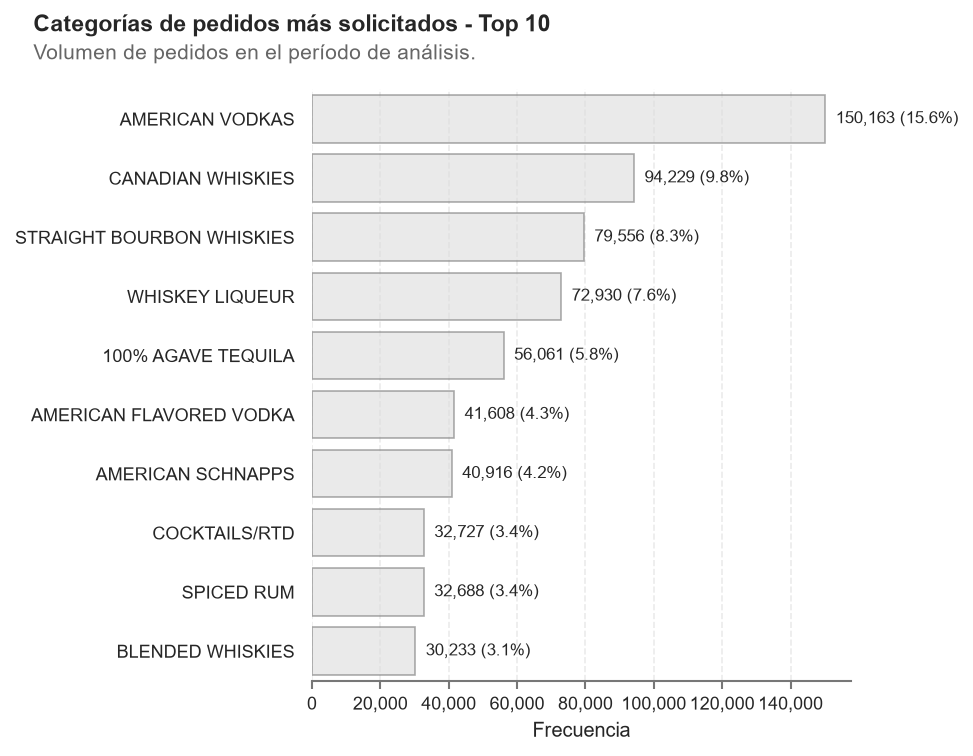

Guardado como: "s_04_01_top_10_categorias.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/01. Formación académica/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_01_top_10_categorias.png')

In [21]:
plot_cat_function_01(
    df_param = df_01,
    column_param = 'category_name',
    top_param = 10,
    suptitle_param = 'Categorías de pedidos más solicitados - Top 10',
    text_param = 'Volumen de pedidos en el período de análisis.',
    file_param = 's_04_01_top_10_categorias.png',
    show_param = True )

<h5 style="font-weight: bold">Descripción del producto</h5>

In [22]:
df_01.\
    get_column('im_desc').\
    value_counts(name = 'count_0', sort = True).\
    with_columns( (pl.col('count_0') / pl.sum('count_0')).alias('ptc_0') )

im_desc,count_0,ptc_0
cat,u32,f64
"""TITOS HANDMADE VODKA""",32326,0.033526
"""FIREBALL CINNAMON WHISKEY""",23670,0.024549
"""BLACK VELVET""",23216,0.024078
"""HAWKEYE VODKA""",21414,0.022209
"""FIREBALL CINNAMON WHISKEY MINI…",13497,0.013998
…,…,…
"""ANGOSTURA 5YR GOLD RUM""",1,0.000001
"""HA OLD FORESTER SINGLE BARREL …",1,0.000001
"""CM OBTAINIUM BLENDED WHISKEY""",1,0.000001


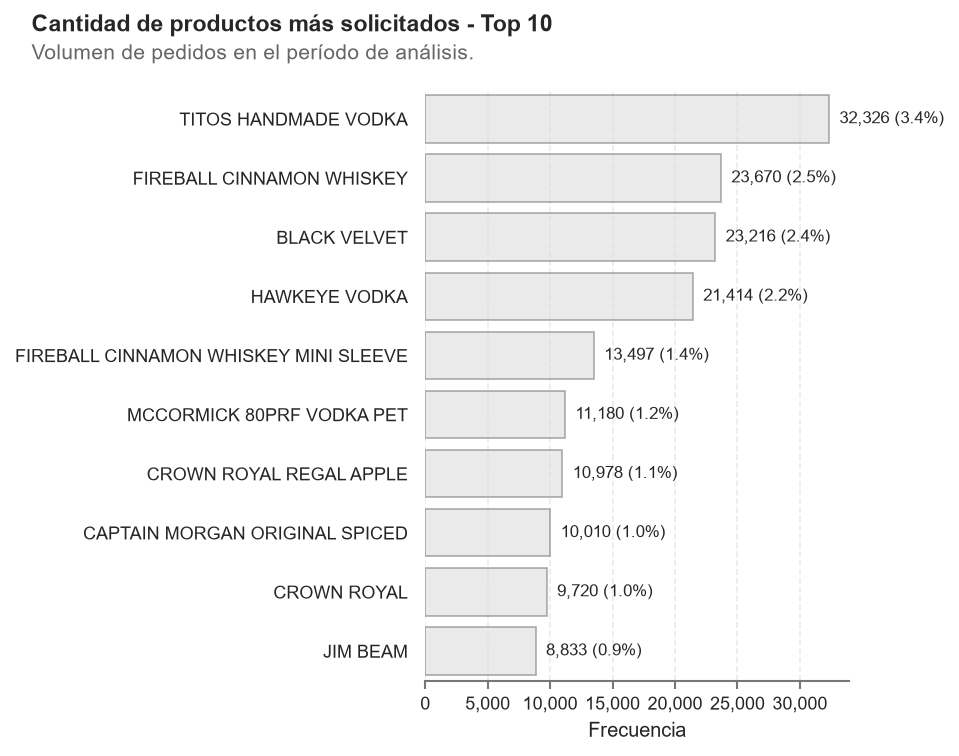

Guardado como: "s_04_02_top_10_productos.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/01. Formación académica/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_02_top_10_productos.png')

In [23]:
plot_cat_function_01(
    df_param = df_01,
    column_param = 'im_desc',
    top_param = 10,
    suptitle_param = 'Cantidad de productos más solicitados - Top 10',
    text_param = 'Volumen de pedidos en el período de análisis.',
    file_param = 's_04_02_top_10_productos.png',
    show_param = True )

<h5 style="font-weight: bold">Tipo de botellas en las órdenes</h5>

Aunque medir mililitros puede conducir a variables continuas, las botellas almacenan (en general) volúmenes estándar. Esta característica lleva a que esta variable sea tratada de forma categórica para el caso de estudio.

Dentro del dataframe existen 13 tipos de botellas diferencias por su tamaño.

In [24]:
df_01.get_column('bottle_volume_ml').n_unique()

13

In [25]:
df_01.\
    get_column('bottle_volume_ml').\
    value_counts(name = 'count_0', sort = True).\
    with_columns( (pl.col('count_0') / pl.sum('count_0')).alias('ptc_0') )

bottle_volume_ml,count_0,ptc_0
str,u32,f64
"""750.0""",393380,0.407983
"""1750.0""",162233,0.168255
"""50.0""",150624,0.156215
"""375.0""",113959,0.118189
"""1000.0""",83305,0.086397
…,…,…
"""25.0""",729,0.000756
"""3000.0""",121,0.000125
"""20.0""",90,0.000093


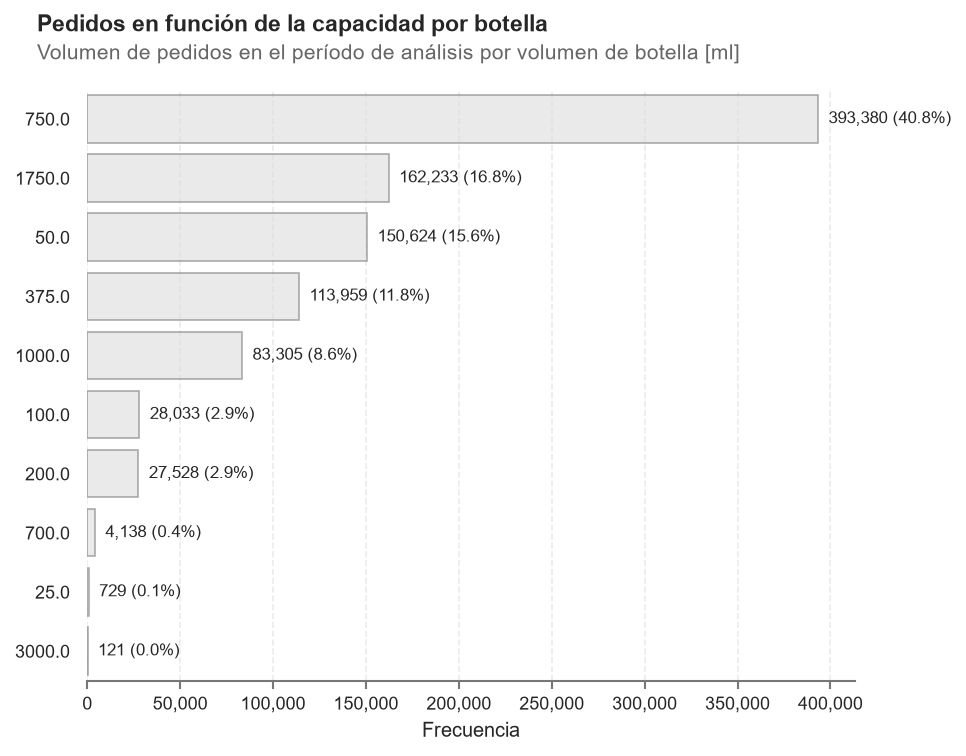

Guardado como: "s_04_03_bottle_volume_ml.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/01. Formación académica/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/s_04_03_bottle_volume_ml.png')

In [26]:
plot_cat_function_01(
    df_param = df_01,
    column_param = 'bottle_volume_ml',
    top_param = 10,
    suptitle_param = 'Pedidos en función de la capacidad por botella',
    text_param = 'Volumen de pedidos en el período de análisis por volumen de botella [ml]',
    file_param = 's_04_03_bottle_volume_ml.png',
    show_param = True )

<h4 style="color:#05856d">3.2. Variables numéricas y de fecha</h4>

¿Cuáles son las variables numéricas y de fecha disponibles?

In [27]:
# Variables categóricas
df_01.select( (cs.string() | cs.categorical()) - cs.by_name('product_code') ).glimpse()

# Vriables numéricas y de fecha
df_01.select(cs.numeric() | cs.by_name('ordered_on')).glimpse()

Rows: 964207
Columns: 4
$ bottle_volume_ml  <str> '750.0', '1750.0', '375.0', '50.0', '1750.0', '375.0', '375.0', '750.0', '750.0', '50.0'
$ category_name     <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ im_desc           <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ period_ordered_on <cat> 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02

Rows: 964207
Columns: 6
$ item_no        <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ ordered_on    <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18
$ pack           <i64> 12, 6, 24, 10, 6, 24, 24, 12, 12, 1

¿Cuál es el espacio de tiempo en el cual se capturaron los datos?

In [28]:
print(f"Fecha más antigua disponible: {df_01.get_column('ordered_on').min()}")
print(f"Fecha más actual disponible: {df_01.get_column('ordered_on').max()}")

Fecha más antigua disponible: 2026-01-01
Fecha más actual disponible: 2026-05-30


¿Cuál es la distribución de las botellas ordenadas por pedido?

Para dibujar la distribución primero es necesario agrupar la cantidad de botellas compradas por día

In [62]:
df_01.glimpse()

Rows: 964207
Columns: 11
$ bottle_volume_ml   <str> '750.0', '1750.0', '375.0', '50.0', '1750.0', '375.0', '375.0', '750.0', '750.0', '50.0'
$ category_name      <cat> BLENDED WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, CANADIAN WHISKIES, SPICED RUM, SPICED RUM, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES, STRAIGHT BOURBON WHISKIES
$ im_desc            <cat> RED STAG BLACK CHERRY, BLACK VELVET, BLACK VELVET, CROWN ROYAL MINI, ADMIRAL NELSON SPICED, ADMIRAL NELSON SPICED, JIM BEAM, JIM BEAM APPLE, JIM BEAM HONEY, JIM BEAM MINI
$ item_no            <i64> 27544, 11788, 11774, 11290, 43028, 43024, 19064, 27783, 27410, 19061
$ ordered_on        <date> 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18, 2026-02-18
$ pack               <i64> 12, 6, 24, 10, 6, 24, 24, 12, 12, 12
$ period_ordered_on  <cat> 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02, 2026-02
$ prod

In [59]:
df_01.select('store_no').n_unique()

2152

In [57]:
df_01.group_by('ordered_on').agg(pl.sum('sales_bottles'))

ordered_on,sales_bottles
date,i64
2026-01-01,96
2026-05-12,129156
2026-05-15,121670
2026-01-04,13838
2026-05-09,29400
…,…
2026-05-06,119836
2026-04-27,105167
2026-04-24,122605


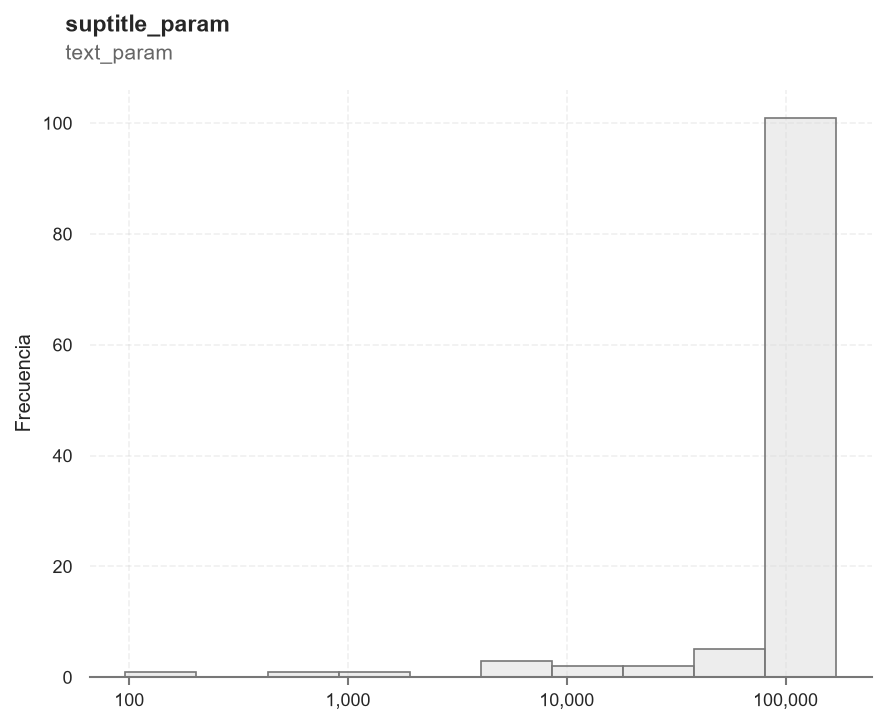

In [61]:
sns.set_theme(
    context = 'paper',
    style = 'white',
    rc = {'axes.grid': True, 'grid.linestyle': '--', 'grid.alpha': 0.3})

g = sns.displot(
    data = df_01.group_by('ordered_on').agg(pl.sum('sales_bottles')),
    x = 'sales_bottles',
    kind = 'hist',
    bins = 10,
    log_scale = (True, False),       # Escala logarítmica en base 10: eje "x" y eje "y"
    color = '#DCDCDC',
    edgecolor = '#777777',
    element = 'bars',
    alpha = 0.5,
    height = 5,
    aspect = 1.2 )

g.despine(left = True, bottom = False)
g.set_axis_labels( x_var = '', y_var = 'Frecuencia' )
g.figure.subplots_adjust(top = 0.90)

g.figure.suptitle(
        'suptitle_param',
        x = 0.08,
        y = 1.00,
        ha = 'left',
        weight = 'bold',
        size = 11 )

g.figure.text(
    x = 0.08,
    y = 0.94,
    s = 'text_param',
    ha = 'left',
    fontsize = 10,
    color = '#666666' )

for ax in g.axes.flat:
    ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
    ax.tick_params(axis = 'x', bottom = True, length = 4, color = '#777777')
    ax.spines['bottom'].set_color('#777777')

plt.show()

In [97]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import polars as pl
from pyprojroot import here
import seaborn as sns


def plot_boxplot_log_01(
    *,
    df_param: pl.DataFrame,
    x_col: str,
    y_col: str,
    suptitle_param: str,
    text_param: str,
    file_param: str,
    show_param: bool = True
) -> Path:
    """
    Genera, personaliza y exporta un boxplot con escala logarítmica en el eje Y.
    """
    # 1. Configuración del tema Seaborn
    sns.set_theme(
        context = 'paper',
        style = 'white',
        rc = {'axes.grid': True, 'grid.linestyle': '--', 'grid.alpha': 0.3}
    )

    # 2. Creación del lienzo
    fig, ax = plt.subplots(figsize = (7, 4.5))

    # 3. Gráfico boxplot
    sns.boxplot(
        data = df_param,
        x = x_col,
        y = y_col,
        color = '#DCDCDC',
        linecolor = '#555555',
        fliersize = 2.5,
        flierprops = {'markerfacecolor': '#999999', 'markeredgecolor': 'none'},
        width = 0.5,
        ax = ax
    )

    # 4. Escala logarítmica y formato en eje Y
    ax.set_yscale('log')
    ax.yaxis.set_major_formatter(ticker.ScalarFormatter())
    ax.yaxis.get_major_formatter().set_scientific(False)

    # 5. Despine y etiquetas de ejes
    sns.despine(ax = ax, offset = 10, trim = True)
    ax.set_xlabel('Período', labelpad = 8)
    ax.set_ylabel('Botellas vendidas (escala log)', labelpad = 8)
    ax.tick_params(axis = 'both', colors = '#555555')

    # 6. Título y subtítulo
    fig.suptitle(
        suptitle_param,
        x = 0.05,
        y = 0.98,
        ha = 'left',
        weight = 'bold',
        size = 11
    )

    fig.text(
        x = 0.05,
        y = 0.93,
        s = text_param,
        ha = 'left',
        fontsize = 9,
        color = '#666666'
    )

    fig.subplots_adjust(top = 0.85)

    # 7. Exportación
    file_destiny = here() / '05_graphs' / file_param
    file_destiny.parent.mkdir(parents = True, exist_ok = True)

    # fig.savefig(
    #     file_destiny,
    #     dpi = 300,
    #     bbox_inches = 'tight',
    #     facecolor = 'white'
    # )

    if show_param:
        plt.show()
    else:
        plt.close(fig)

    print(f'Guardado como: "{file_param}" en 05_graphs')
    return file_destiny

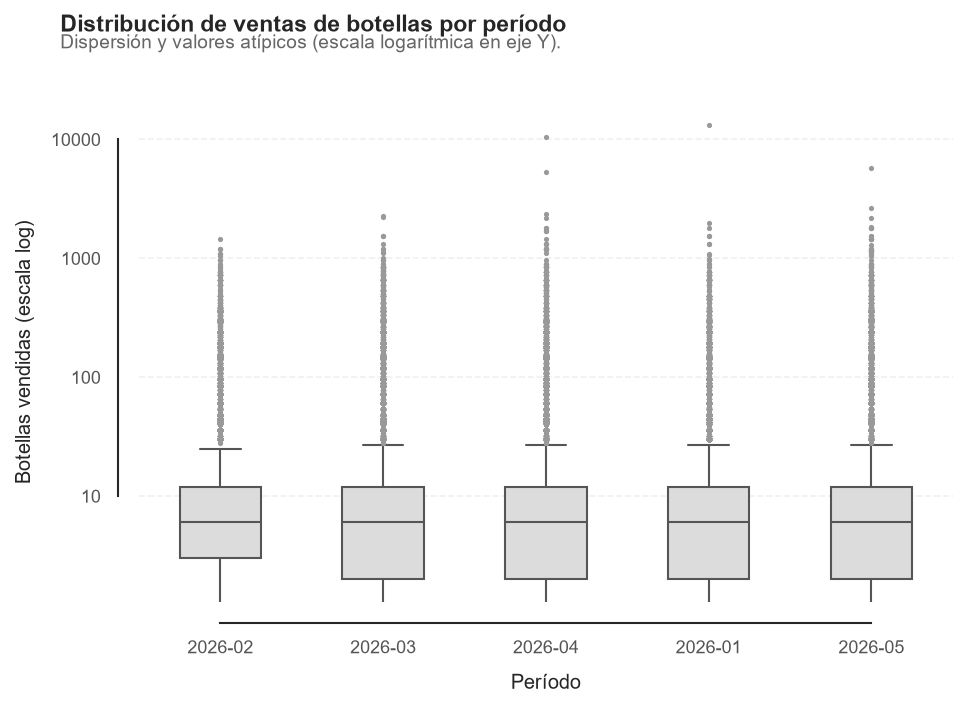

Guardado como: "02_boxplot_ventas_periodo_log.png" en 05_graphs


WindowsPath('g:/My Drive/01. Formación/01. Formación académica/02 Maestría en ciencia de datos UCB/Segunda fase/Proyecto_UCB_2da_fase/05_graphs/02_boxplot_ventas_periodo_log.png')

In [98]:
plot_boxplot_log_01(
    df_param = df_01,
    x_col = 'period_ordered_on',
    y_col = 'sales_bottles',
    suptitle_param = 'Distribución de ventas de botellas por período',
    text_param = 'Dispersión y valores atípicos (escala logarítmica en eje Y).',
    file_param = '02_boxplot_ventas_periodo_log.png',
    show_param = True
)

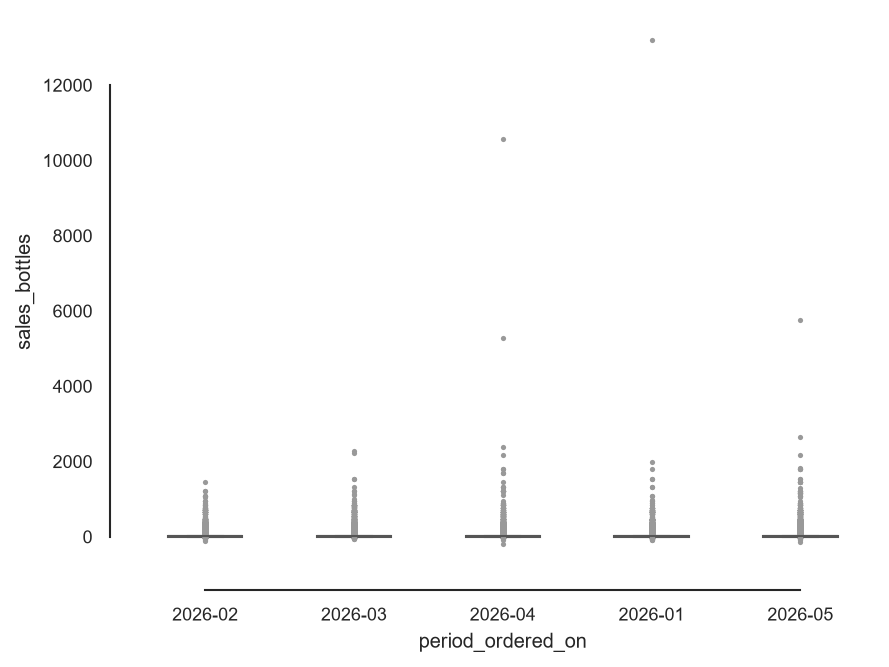

In [96]:
import seaborn as sns
from matplotlib import ticker

sns.set_theme( context = 'paper', style = 'white')


sns.boxplot(
    data = df_01,
    x = 'period_ordered_on',
    y = 'sales_bottles',
    color = '#DCDCDC',
    linecolor = '#555555',
    fliersize = 2.5,
    flierprops = {'markerfacecolor': '#999999', 'markeredgecolor': 'none'},
    width = 0.5
)



sns.despine(offset=10, trim=True)

<h3 style="color:#05856d">4. Análisis relacional</h3>
<hr>

<h4 style="color:#05856d">4.1. Asociaciones</h4>

<h4 style="color:#05856d">4.2. Correlaciones</h4>

<h4 style="color:#05856d">4.3. Comparaciones</h4>